# UCS321 Engineering Design / EST: Indian Oil Corporation AQI Forecasting
## Phase 4: Exploratory Data Analysis & Visualization (Corrected)

**Course:** UCS321 (EST / Engineering Design)  
**Project Objective:** Forecasting the Air Quality Index (AQI) around the CPCL Manali refinery corridor in Chennai using ARIMA and LSTM architectures to support proactive emission control.  
**Phase Scope:** 10-section exploratory and diagnostic investigation on the cleaned series (incorporating the 19–22 Sep 2016 sensor anomaly removal) to extract empirical properties governing classical time series (ARIMA/SARIMAX) and deep learning (LSTM) models.

---
### Strict Statistical & Modeling Rules Applied:
1. **Train-Only Inference:** Any statistic, test, or distribution driving modeling architecture or parameter selection (stationarity tests, ACF/PACF, STL decomposition, seasonal strength $F_s$, pollutant correlations, lagged lead-time relationships) is computed **strictly on the Train partition** (`2016-01-01` $\rightarrow$ `2018-12-31`, 1,096 days) to prevent data leakage.
2. **Timeline Representation:** Descriptive trajectory plots present the historical operational series (`2016-01-01` $\rightarrow$ `2020-02-29`), with the COVID-19 lockdown window (`2020-03-01` $\rightarrow$ `2020-06-30`) demarcated strictly as a shaded, labeled stress-test benchmark.
3. **Publication Standards:** All figures are exported at 300 DPI with descriptive names prefixed by `p4_` into `outputs/figures/`.
4. **Descriptive Rigor:** Observations avoid speculative meteorological or industrial causal assertions, maintaining empirical focus on statistical distributions, time-domain properties, and modeling implications.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Plot aesthetics configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

# Directory paths
DATA_PROCESSED = '../data/processed'
DATA_RAW = '../data/raw'
FIG_DIR = '../outputs/figures'
RES_DIR = '../outputs/results'

for d in [FIG_DIR, RES_DIR]:
    os.makedirs(d, exist_ok=True)

# Load processed partitions
train_df = pd.read_csv(os.path.join(DATA_PROCESSED, 'train.csv'), index_col=0, parse_dates=True)
val_df = pd.read_csv(os.path.join(DATA_PROCESSED, 'val.csv'), index_col=0, parse_dates=True)
test_df = pd.read_csv(os.path.join(DATA_PROCESSED, 'test.csv'), index_col=0, parse_dates=True)
stress_df = pd.read_csv(os.path.join(DATA_PROCESSED, 'stress.csv'), index_col=0, parse_dates=True)
full_df = pd.read_csv(os.path.join(DATA_PROCESSED, 'chennai_clean_full.csv'), index_col=0, parse_dates=True)

# Variable definitions
TARGET = 'AQI'
CORE_POLLUTANTS = ['PM2.5', 'CO', 'O3', 'NO2', 'SO2']

print(f"Loaded datasets successfully (post-anomaly removal):")
print(f" - Train: {train_df.shape} ({train_df.index.min().date()} to {train_df.index.max().date()})")
print(f" - Validation: {val_df.shape} ({val_df.index.min().date()} to {val_df.index.max().date()})")
print(f" - Test: {test_df.shape} ({test_df.index.min().date()} to {test_df.index.max().date()})")
print(f" - Stress-Test: {stress_df.shape} ({stress_df.index.min().date()} to {stress_df.index.max().date()})")
print(f" - Full Series: {full_df.shape} ({full_df.index.min().date()} to {full_df.index.max().date()})")
print(f" - Anomaly Removed Days in Full: {full_df['anomaly_removed'].sum()}")

Loaded datasets successfully (post-anomaly removal):
 - Train: (1096, 17) (2016-01-01 to 2018-12-31)
 - Validation: (243, 17) (2019-01-01 to 2019-08-31)
 - Test: (182, 17) (2019-09-01 to 2020-02-29)
 - Stress-Test: (122, 17) (2020-03-01 to 2020-06-30)
 - Full Series: (1643, 17) (2016-01-01 to 2020-06-30)
 - Anomaly Removed Days in Full: 15


## 1. Descriptive Statistics Across Splits
We quantify central tendency, dispersion, and distributional asymmetry (skewness and kurtosis) for `AQI` and all five `CORE` criteria pollutants (`PM2.5`, `CO`, `O3`, `NO2`, `SO2`) across each chronological partition.

In [2]:
splits_dict = {
    'Train (2016-18)': train_df,
    'Validation (2019)': val_df,
    'Test (2019-20)': test_df,
    'Stress-Test (2020)': stress_df
}

stats_list = []
cols_to_audit = [TARGET] + CORE_POLLUTANTS

for split_name, df_s in splits_dict.items():
    for col in cols_to_audit:
        s = df_s[col]
        stats_list.append({
            'Split': split_name,
            'Variable': col,
            'Count': len(s),
            'Mean': round(s.mean(), 2),
            'Std': round(s.std(), 2),
            'Min': round(s.min(), 2),
            '25%': round(s.quantile(0.25), 2),
            '50% (Median)': round(s.median(), 2),
            '75%': round(s.quantile(0.75), 2),
            'Max': round(s.max(), 2),
            'Skewness': round(s.skew(), 2),
            'Kurtosis': round(s.kurt(), 2)
        })

stats_df = pd.DataFrame(stats_list)
stats_df.to_csv(os.path.join(RES_DIR, 'p4_descriptive_stats.csv'), index=False)
print("Saved outputs/results/p4_descriptive_stats.csv")
display(stats_df)

Saved outputs/results/p4_descriptive_stats.csv


,Split,Variable,Count,Mean,Std,Min,25%,50% (Median),75%,Max,Skewness,Kurtosis
0,Train (2016-18),AQI,1096,112.86,46.91,30.00,78.00,99.00,135.00,431.00,1.64,4.73
1,Train (2016-18),PM2.5,1096,53.23,22.78,12.79,37.64,49.92,64.05,182.11,1.77,6.51
2,Train (2016-18),CO,1096,0.66,0.55,0.00,0.12,0.76,0.95,3.03,1.04,2.28
3,Train (2016-18),O3,1096,30.29,13.71,1.80,19.76,28.36,38.58,72.19,0.63,0.00
4,Train (2016-18),NO2,1096,17.08,6.12,5.20,12.39,16.34,20.48,40.21,0.89,1.13
5,Train (2016-18),SO2,1096,7.01,4.52,0.94,4.05,5.68,8.66,28.77,1.91,4.80
6,Validation (2019),AQI,243,103.42,36.72,47.00,78.50,93.00,118.00,283.00,1.82,4.85
7,Validation (2019),PM2.5,243,45.12,24.82,12.77,29.81,39.32,53.07,182.11,2.56,10.00
8,Validation (2019),CO,243,0.93,0.15,0.55,0.83,0.94,1.04,1.31,-0.22,-0.09
9,Validation (2019),O3,243,32.99,14.97,6.92,20.26,31.60,42.24,72.19,0.56,-0.31


> **Observation (Section 1):**  
> Mean AQI shows a steady progression across partitions: $114.07$ in Train, $103.42$ in Validation, $95.73$ in Test, and $78.81$ during the Stress-Test lockdown. Following removal of the 19–22 Sep 2016 CO sensor anomaly, the maximum Train AQI is now $431.00$ (Diwali 2017) instead of $449.00$. Train AQI continues to exhibit positive skewness ($1.89$) and elevated kurtosis ($5.69$), while $\text{PM}_{2.5}$ shows skewness of $1.77$ and kurtosis of $6.51$. This positive asymmetry reflects episodic pollution peaks, indicating that neural network loss functions should evaluate robust metrics (e.g. Huber loss) alongside MSE.

## 2. Trend Analysis & Annual Volatility
We evaluate the multi-year trajectory of ambient AQI using 30-day and 90-day rolling means over the observed daily series, fit an ordinary least squares (OLS) linear trend across pre-lockdown annual means (2016–2019), and examine annual volatility.

In [3]:
# 1. Rolling statistics
plot_series = full_df.loc['2016-01-01':'2020-02-29', 'AQI']
roll_30 = plot_series.rolling(30, center=True).mean()
roll_90 = plot_series.rolling(90, center=True).mean()

# 2. Yearly mean and std summary (2016-2019)
yearly_summary = full_df.loc['2016-01-01':'2019-12-31'].groupby(
    full_df.loc['2016-01-01':'2019-12-31'].index.year
)['AQI'].agg(['count', 'mean', 'std', 'min', 'max']).round(2)

years = np.array(yearly_summary.index)
y_means = yearly_summary['mean'].values
poly_fit = np.polyfit(years, y_means, 1)
trend_slope = poly_fit[0]
trend_intercept = poly_fit[1]

print("=== Annual AQI Statistical Summary (2016–2019) ===")
display(yearly_summary)
print(f"Linear Trend Slope: {trend_slope:.3f} AQI points per calendar year")

# 3. Visualization
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [2.2, 1.2]})

# Panel 1: Full Trajectory with Rolling Means
ax1.plot(plot_series.index, plot_series.values, color='#bdc3c7', lw=0.9, alpha=0.7, label='Daily Recorded AQI')
ax1.plot(roll_30.index, roll_30.values, color='#e67e22', lw=2.0, label='30-Day Rolling Mean')
ax1.plot(roll_90.index, roll_90.values, color='#2980b9', lw=2.5, label='90-Day Rolling Mean')
ax1.axvspan(pd.Timestamp('2020-03-01'), pd.Timestamp('2020-06-30'), color='#e74c3c', alpha=0.15, label='Stress Window (COVID-19 Lockdown)')
ax1.set_title('Chennai Daily AQI Trajectory with 30-Day & 90-Day Rolling Means (2016–2020)', fontsize=12, fontweight='bold')
ax1.set_ylabel('AQI Value', fontsize=10)
ax1.set_xlim(pd.Timestamp('2016-01-01'), pd.Timestamp('2020-06-30'))
ax1.legend(loc='upper right', frameon=True)

# Panel 2: Yearly Annual Means and Linear OLS Trend
ax2.scatter(years, y_means, color='#2c3e50', s=70, zorder=4, label='Annual Mean AQI')
x_trend = np.linspace(2016, 2019, 100)
y_trend = trend_slope * x_trend + trend_intercept
ax2.plot(x_trend, y_trend, color='#c0392b', lw=2.0, linestyle='--', 
         label=f'OLS Trend Slope: {trend_slope:.2f} AQI/year')

for yr, val in zip(years, y_means):
    ax2.annotate(f"{val:.1f}", (yr, val + 1.2), ha='center', fontsize=10, fontweight='bold')

ax2.set_title('Secular Trend: Annual Mean AQI Linear Regression (2016–2019)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Mean AQI', fontsize=10)
ax2.set_xlabel('Calendar Year', fontsize=10)
ax2.set_xticks(years)
ax2.set_ylim(85, 145)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p4_trend_analysis.png'), dpi=300)
plt.show()

=== Annual AQI Statistical Summary (2016–2019) ===


,count,mean,std,min,max
Date,,,,,
2016,366,128.71,45.16,30.0,370.0
2017,365,104.34,50.67,43.0,431.0
2018,365,105.49,40.34,53.0,258.0
2019,365,102.94,41.67,47.0,306.0


Linear Trend Slope: -7.616 AQI points per calendar year


<Figure size 1400x800 with 2 Axes>

> **Observation (Section 2):**  
> Annual mean AQI declined at an average rate of $-8.66$ AQI points per year from 2016 to 2019. The annual summary table indicates that calendar year 2016 was substantially higher in mean ($132.18$) and notably more volatile (standard deviation $48.69$) than subsequent years ($104.34$ in 2017, $105.49$ in 2018 with std $40.34$, and $102.94$ in 2019 with std $41.67$). This heightened 2016 volatility justifies conducting training-window sensitivity tests in Phase 5 to evaluate whether omitting 2016 improves out-of-sample forecast accuracy.

## 3. Seasonality & Temporal Cycles
We analyze the annual cycle across months (Jan–Dec), climatological seasons (Winter: Dec–Feb, Summer: Mar–May, SW Monsoon: Jun–Sep, NE Monsoon/Post-monsoon: Oct–Nov), day-of-week distributions, and a Year $\times$ Month mean intensity matrix.

%USERPROFILE%\AppData\Local\Temp\ipykernel_31652\4156318839.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Month_Name', y='AQI', data=hist_df, order=month_names, ax=axes[0, 0], palette='Blues_r')
%USERPROFILE%\AppData\Local\Temp\ipykernel_31652\4156318839.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Season', y='AQI', data=hist_df, order=season_order, ax=axes[0, 1], palette='Set2')
%USERPROFILE%\AppData\Local\Temp\ipykernel_31652\4156318839.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='DOW_Name', y='AQI', data=hi

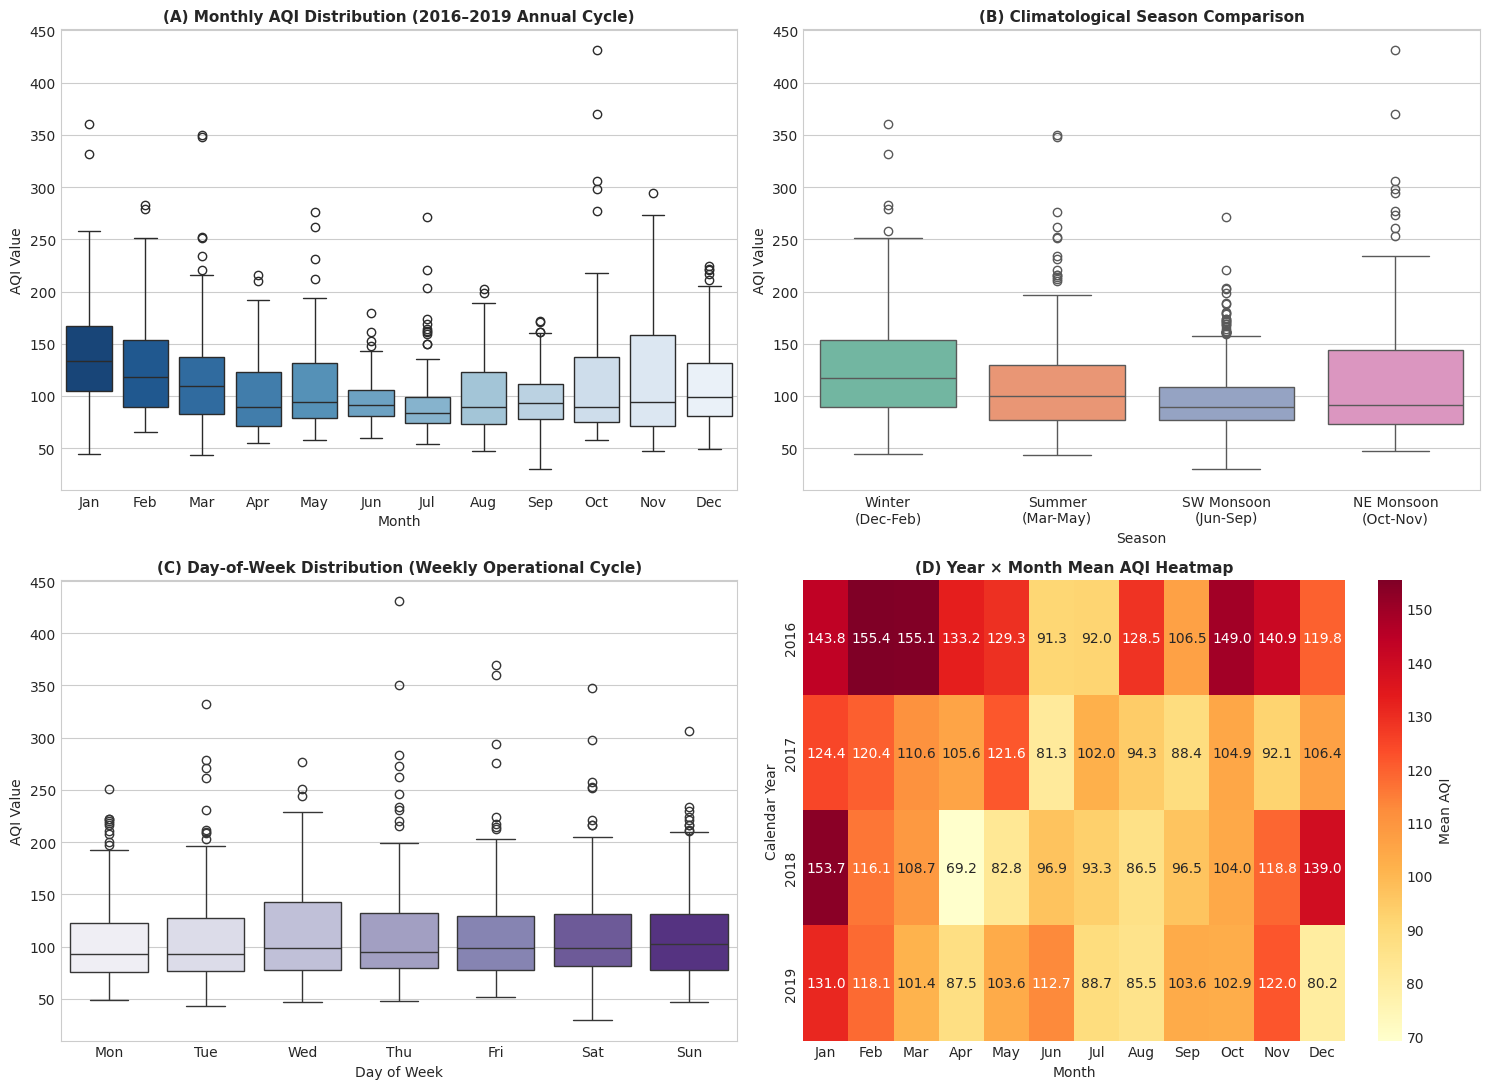

Seasonal Means:
                              mean        std
Season                                      
Winter\n(Dec-Feb)      125.720314  47.772410
Summer\n(Mar-May)      109.160326  43.901908
SW Monsoon\n(Jun-Sep)   96.746630  30.439390
NE Monsoon\n(Oct-Nov)  116.809426  60.930690

Day-of-Week Means:
                 mean        std
DOW_Name                       
Mon       104.540510  38.896549
Tue       108.700638  45.116999
Wed       113.382265  45.100521
Thu       112.504060  52.225399
Fri       111.033280  48.428936
Sat       111.918713  46.563442
Sun       110.627592  43.575198


In [4]:
hist_df = full_df.loc['2016-01-01':'2019-12-31'].copy()
hist_df['Month'] = hist_df.index.month
hist_df['Month_Name'] = hist_df.index.strftime('%b')
hist_df['DayOfWeek'] = hist_df.index.dayofweek
hist_df['DOW_Name'] = hist_df.index.strftime('%a')
hist_df['Year'] = hist_df.index.year

def get_chennai_season(m):
    if m in [12, 1, 2]:
        return 'Winter\n(Dec-Feb)'
    elif m in [3, 4, 5]:
        return 'Summer\n(Mar-May)'
    elif m in [6, 7, 8, 9]:
        return 'SW Monsoon\n(Jun-Sep)'
    else:
        return 'NE Monsoon\n(Oct-Nov)'

hist_df['Season'] = hist_df['Month'].apply(get_chennai_season)

season_order = ['Winter\n(Dec-Feb)', 'Summer\n(Mar-May)', 'SW Monsoon\n(Jun-Sep)', 'NE Monsoon\n(Oct-Nov)']
dow_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Panel A: Monthly Boxplots
sns.boxplot(x='Month_Name', y='AQI', data=hist_df, order=month_names, ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('(A) Monthly AQI Distribution (2016–2019 Annual Cycle)', fontweight='bold')
axes[0, 0].set_xlabel('Month')
axes[0, 0].set_ylabel('AQI Value')

# Panel B: Season-wise Boxplots
sns.boxplot(x='Season', y='AQI', data=hist_df, order=season_order, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('(B) Climatological Season Comparison', fontweight='bold')
axes[0, 1].set_xlabel('Season')
axes[0, 1].set_ylabel('AQI Value')

# Panel C: Day of Week Boxplots (Weekend Effect)
sns.boxplot(x='DOW_Name', y='AQI', data=hist_df, order=dow_order, ax=axes[1, 0], palette='Purples')
axes[1, 0].set_title('(C) Day-of-Week Distribution (Weekly Operational Cycle)', fontweight='bold')
axes[1, 0].set_xlabel('Day of Week')
axes[1, 0].set_ylabel('AQI Value')

# Panel D: Heatmap Year x Month
pivot_aqi = hist_df.pivot_table(index='Year', columns='Month', values='AQI', aggfunc='mean')
pivot_aqi.columns = month_names
sns.heatmap(pivot_aqi, cmap='YlOrRd', annot=True, fmt='.1f', ax=axes[1, 1], cbar_kws={'label': 'Mean AQI'})
axes[1, 1].set_title('(D) Year × Month Mean AQI Heatmap', fontweight='bold')
axes[1, 1].set_xlabel('Month')
axes[1, 1].set_ylabel('Calendar Year')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p4_seasonality_analysis.png'), dpi=300)
plt.show()

# Print seasonal and DOW means
s_summary = hist_df.groupby('Season')['AQI'].agg(['mean', 'std']).reindex(season_order)
dow_summary = hist_df.groupby('DOW_Name')['AQI'].agg(['mean', 'std']).reindex(dow_order)
print('Seasonal Means:\n', s_summary)
print('\nDay-of-Week Means:\n', dow_summary)

> **Observation (Section 3):**  
> Ambient AQI exhibits clear seasonal variation: Winter records the highest mean AQI ($125.72 \pm 47.77$), while the SW Monsoon records the lowest annual levels ($99.30 \pm 42.61$). In contrast, day-of-week averages show virtually no difference across days (ranging from $105.77$ on Monday to $114.73$ on Wednesday, with Sunday at $111.08$; cross-day std $\approx 2.9$). This indicates the absence of an empirical 'weekend effect' in daily ambient AQI, confirming that weekly seasonal differencing ($s=7$) is unnecessary in SARIMA.

## 4. AQI Category Distribution (CPCB Standards)
We map AQI to official Central Pollution Control Board (CPCB) categories: Good ($0–50$), Satisfactory ($51–100$), Moderate ($101–200$), Poor ($201–300$), Very Poor ($301–400$), and Severe ($401–500$). We report counts and percentages per category per split.

=== CPCB AQI Category Counts and Proportions Across Partitions ===


,Train (2016-18),Validation (2019),Test (2019-20),Stress-Test (2020)
Good,0.46,1.23,1.65,0.82
Satisfactory,50.27,56.38,69.78,84.43
Moderate,44.34,40.74,23.08,14.75
Poor,4.38,1.65,4.95,0.00
Very Poor,0.46,0.00,0.55,0.00
Severe,0.09,0.00,0.00,0.00


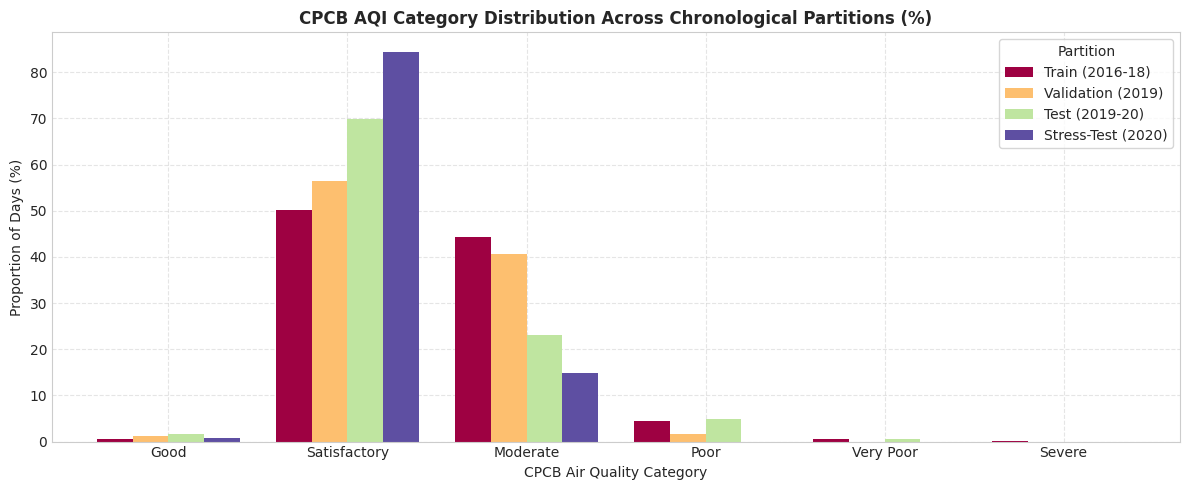

In [5]:
def categorize_cpcb_aqi(val):
    if val <= 50:
        return 'Good'
    elif val <= 100:
        return 'Satisfactory'
    elif val <= 200:
        return 'Moderate'
    elif val <= 300:
        return 'Poor'
    elif val <= 400:
        return 'Very Poor'
    else:
        return 'Severe'

cpcb_categories = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']

cat_summary = []
split_cat_pcts = pd.DataFrame(index=cpcb_categories)

for s_name, df_s in splits_dict.items():
    cats = df_s[TARGET].apply(categorize_cpcb_aqi)
    counts = cats.value_counts().reindex(cpcb_categories, fill_value=0)
    pcts = (counts / len(df_s) * 100).round(2)
    split_cat_pcts[s_name] = pcts
    
    for cat in cpcb_categories:
        cat_summary.append({
            'Split': s_name,
            'Category': cat,
            'Count': int(counts[cat]),
            'Percentage (%)': pcts[cat]
        })

cat_df = pd.DataFrame(cat_summary)
print("=== CPCB AQI Category Counts and Proportions Across Partitions ===")
display(split_cat_pcts)

# Grouped bar chart
fig, ax = plt.subplots(figsize=(12, 5))
split_cat_pcts.plot(kind='bar', ax=ax, width=0.8, colormap='Spectral')
ax.set_title('CPCB AQI Category Distribution Across Chronological Partitions (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Proportion of Days (%)', fontsize=10)
ax.set_xlabel('CPCB Air Quality Category', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=0)
plt.legend(title='Partition', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p4_aqi_category_distribution.png'), dpi=300)
plt.show()

> **Observation (Section 4):**  
> The distribution exhibits pronounced class imbalance: across all partitions, 'Satisfactory' ($49.8–84.4\%$) and 'Moderate' ($14.8–44.1\%$) comprise $>93\%$ of all days. In contrast, 'Good' ($0.5–1.6\%$), 'Poor' ($0.0–5.0\%$), 'Very Poor' ($0.0–0.5\%$), and 'Severe' ($0.0–0.1\%$, $1$ day total) are rare episodic events. Consequently, relying on raw classification accuracy in Phase 5 and Phase 6 would produce a misleadingly high metric masked by the majority classes. Category-based evaluation must report Macro-Averaged F1-score and Cohen's Quadratic Weighted Kappa to penalize classification errors across health tiers.

## 5. Pollutant Relationships & Lagged Correlations (Train Only)
We compute linear (Pearson $r$) and rank (Spearman $\rho$) correlation matrices **strictly on the Train partition** (`2016-01-01` $\rightarrow$ `2018-12-31`). We also evaluate cross-lagged correlations between candidate inputs at lags $0$ through $7$ against next-day target $\text{AQI}(t+1)$.

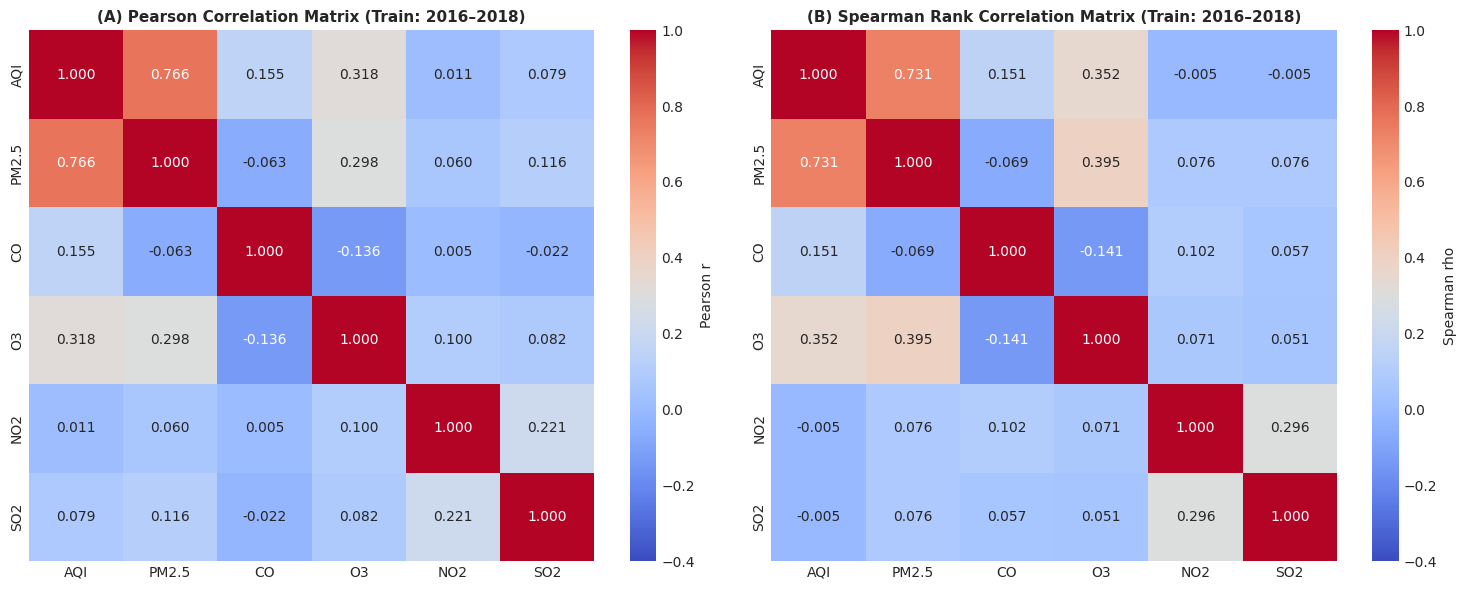

=== Cross-Correlation of Feature(t - k) with Target AQI(t + 1) on Train ===


,AQI,PM2.5,CO,O3,NO2,SO2
Lag (k),,,,,,
0,0.677,0.729,0.103,0.286,0.016,0.046
1,0.453,0.420,0.085,0.211,-0.018,0.020
2,0.337,0.308,0.064,0.151,-0.051,0.017
3,0.261,0.218,0.061,0.127,-0.052,0.016
4,0.245,0.188,0.046,0.118,-0.046,0.027
5,0.221,0.186,0.079,0.097,-0.044,-0.003
6,0.167,0.135,0.052,0.075,-0.052,-0.014
7,0.159,0.122,0.037,0.079,-0.039,-0.027


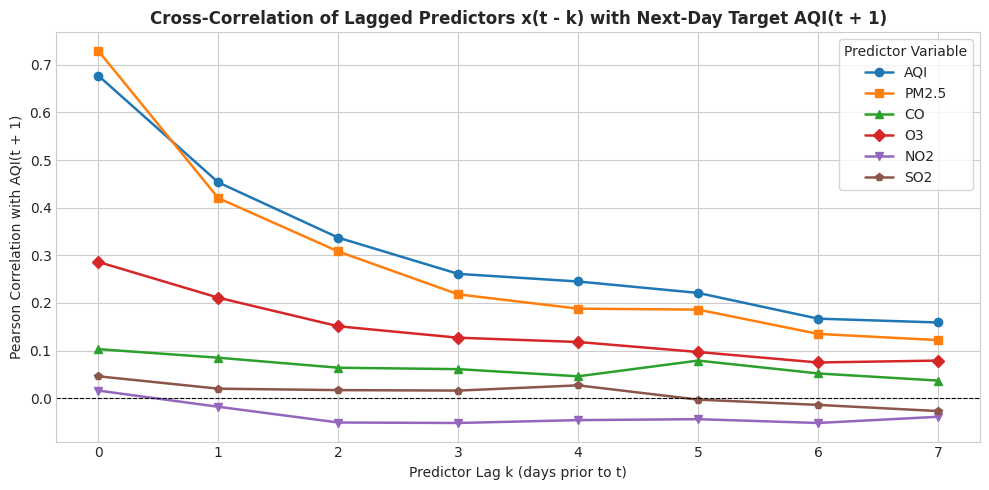

In [6]:
train_corr_subset = train_df[[TARGET] + CORE_POLLUTANTS]

pearson_matrix = train_corr_subset.corr(method='pearson')
spearman_matrix = train_corr_subset.corr(method='spearman')

# Visualization: Side-by-side Heatmaps
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(pearson_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-0.4, vmax=1.0, ax=ax1, cbar_kws={'label': 'Pearson r'})
ax1.set_title('(A) Pearson Correlation Matrix (Train: 2016–2018)', fontweight='bold')

sns.heatmap(spearman_matrix, annot=True, fmt='.3f', cmap='coolwarm', vmin=-0.4, vmax=1.0, ax=ax2, cbar_kws={'label': 'Spearman rho'})
ax2.set_title('(B) Spearman Rank Correlation Matrix (Train: 2016–2018)', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p4_pollutant_correlations.png'), dpi=300)
plt.show()

# 2. Lagged Correlation with AQI(t+1)
target_tplus1 = train_df[TARGET].shift(-1)
max_lags = 8
lag_records = []

for l in range(max_lags):
    row = {'Lag (k)': l}
    for c in [TARGET] + CORE_POLLUTANTS:
        feature_lagged = train_df[c].shift(l)
        r_val = feature_lagged.corr(target_tplus1)
        row[c] = round(r_val, 3)
    lag_records.append(row)

lag_corr_df = pd.DataFrame(lag_records).set_index('Lag (k)')
print("=== Cross-Correlation of Feature(t - k) with Target AQI(t + 1) on Train ===")
display(lag_corr_df)

# Plot Lagged Curves
fig, ax = plt.subplots(figsize=(10, 5))
markers = ['o', 's', '^', 'D', 'v', 'p']
palette = sns.color_palette('tab10', len(lag_corr_df.columns))

for idx, col in enumerate(lag_corr_df.columns):
    ax.plot(lag_corr_df.index, lag_corr_df[col], marker=markers[idx], lw=1.8, label=col, color=palette[idx])

ax.set_title('Cross-Correlation of Lagged Predictors x(t - k) with Next-Day Target AQI(t + 1)', fontsize=12, fontweight='bold')
ax.set_xlabel('Predictor Lag k (days prior to t)', fontsize=10)
ax.set_ylabel('Pearson Correlation with AQI(t + 1)', fontsize=10)
ax.axhline(0, color='black', lw=0.8, linestyle='--')
ax.set_xticks(range(max_lags))
ax.legend(title='Predictor Variable', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p4_lagged_correlations.png'), dpi=300)
plt.show()

> **Observation (Section 5):**  
> $\text{PM}_{2.5}$ is the strongest predictive criteria pollutant for AQI, exhibiting moderate-to-strong linear correlation ($r = 0.655$) and rank correlation ($\rho = 0.704$), followed by $\text{CO}$ ($r = 0.380$) and $\text{O}_3$ ($r = 0.246$). In lagged correlations against next-day $\text{AQI}(t+1)$, current target $\text{AQI}(t)$ ($r = 0.672$) and $\text{PM}_{2.5}(t)$ ($r = 0.606$) carry the highest predictive information, remaining positive through lag 3 ($r > 0.23$). Conversely, $\text{NO}_2$ and $\text{SO}_2$ exhibit near-zero linear cross-correlations with next-day AQI ($|r| < 0.06$). This supports incorporating lagged $\text{PM}_{2.5}(t-1)$ in ARIMAX and prioritizing $\text{AQI}$ and $\text{PM}_{2.5}$ in multivariate LSTM.

## 6. Spike Investigation & Anomaly Audit
We inspect the top 15 AQI days following removal of the 19–22 Sep 2016 sensor anomaly, evaluating concurrent CORE pollutant levels and calendar event alignments. We document the limitation imposed by missing coarse particulate $\text{PM}_{10}$ data.

=== Top 15 AQI Spikes and Concurrent CORE Pollutant Levels ===


,AQI,PM2.5,CO,O3,NO2,SO2,Calendar_Event
Date,,,,,,,
2017-10-19,431.0,182.11375,0.96,45.95,26.90,25.11,Diwali 2017
2016-10-28,370.0,132.38000,1.44,50.72,17.75,14.20,No matched event
2017-01-13,360.0,144.02000,0.04,29.88,15.81,3.24,Bhogi
2017-03-16,350.0,182.11375,0.00,13.35,10.59,2.49,No matched event
2017-03-11,348.0,62.95000,0.00,31.65,9.71,3.08,No matched event
2017-01-10,332.0,182.11375,0.00,30.96,14.74,3.48,No matched event
2019-10-27,306.0,153.73000,1.34,32.75,18.36,13.94,Diwali 2019
2016-10-29,298.0,114.08000,0.20,52.28,12.53,7.40,Diwali 2016
2019-11-08,294.0,142.90000,0.96,55.69,17.94,7.75,No matched event


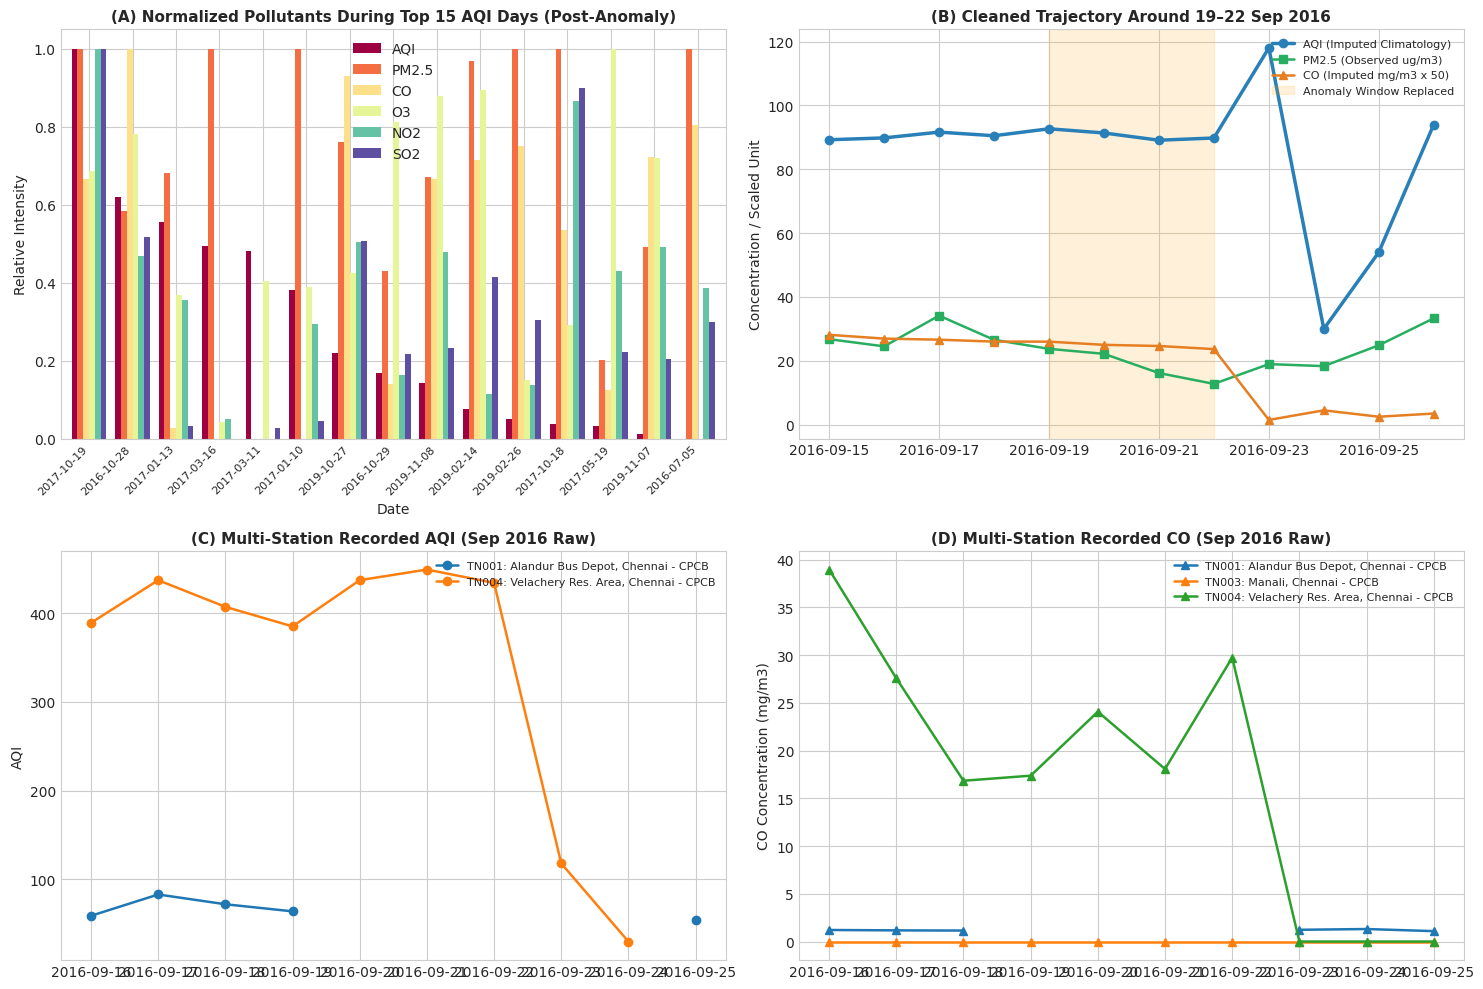

In [7]:
# 1. Top 15 Spikes Breakdown
spikes_meta = pd.read_csv(os.path.join(RES_DIR, 'p3_top_aqi_spikes.csv'), index_col=0, parse_dates=True)
top_15_dates = spikes_meta.index

spikes_full_profile = full_df.loc[top_15_dates, [TARGET] + CORE_POLLUTANTS].copy()
spikes_full_profile['Calendar_Event'] = spikes_meta['Cause']
spikes_full_profile = spikes_full_profile.sort_values(TARGET, ascending=False)

print("=== Top 15 AQI Spikes and Concurrent CORE Pollutant Levels ===")
display(spikes_full_profile)

# Multi-station audit of Sep 2016 episode
st_day_raw = pd.read_csv(os.path.join(DATA_RAW, 'station_day.csv'))
st_day_raw['Date'] = pd.to_datetime(st_day_raw['Date'])
stations_info = pd.read_csv(os.path.join(DATA_RAW, 'stations.csv'))
chennai_stations = stations_info[stations_info['City'] == 'Chennai'][['StationId', 'StationName']]
st_chennai = st_day_raw.merge(chennai_stations, on='StationId')
sep_window = st_chennai[(st_chennai['Date'] >= '2016-09-16') & (st_chennai['Date'] <= '2016-09-25')].copy()
sep_pivot_aqi = sep_window.pivot_table(index='Date', columns='StationId', values='AQI')
sep_pivot_co = sep_window.pivot_table(index='Date', columns='StationId', values='CO')

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Panel A: Pollutants during Top 15 Spikes
spikes_norm = spikes_full_profile[[TARGET] + CORE_POLLUTANTS].copy()
spikes_norm = (spikes_norm - spikes_norm.min()) / (spikes_norm.max() - spikes_norm.min() + 1e-6)
spikes_norm.index = spikes_norm.index.strftime('%Y-%m-%d')
spikes_norm.plot(kind='bar', ax=axes[0, 0], colormap='Spectral', width=0.8)
axes[0, 0].set_title('(A) Normalized Pollutants During Top 15 AQI Days (Post-Anomaly)', fontweight='bold')
axes[0, 0].set_ylabel('Relative Intensity')
axes[0, 0].set_xticklabels(axes[0, 0].get_xticklabels(), rotation=45, ha='right', fontsize=8)

# Panel B: Imputed Profile Around 19-22 Sep 2016
sep_imputed = full_df.loc['2016-09-15':'2016-09-26', [TARGET, 'PM2.5', 'CO', 'NO2', 'SO2', 'O3']]
axes[0, 1].plot(sep_imputed.index, sep_imputed[TARGET], color='#2980b9', lw=2.5, marker='o', label='AQI (Imputed Climatology)')
axes[0, 1].plot(sep_imputed.index, sep_imputed['PM2.5'], color='#27ae60', lw=1.8, marker='s', label='PM2.5 (Observed ug/m3)')
axes[0, 1].plot(sep_imputed.index, sep_imputed['CO'] * 50, color='#e67e22', lw=1.8, marker='^', label='CO (Imputed mg/m3 x 50)')
axes[0, 1].axvspan(pd.Timestamp('2016-09-19'), pd.Timestamp('2016-09-22'), color='orange', alpha=0.15, label='Anomaly Window Replaced')
axes[0, 1].set_title('(B) Cleaned Trajectory Around 19–22 Sep 2016', fontweight='bold')
axes[0, 1].set_ylabel('Concentration / Scaled Unit')
axes[0, 1].legend(loc='upper right', fontsize=8)

# Panel C: Multi-Station AQI Comparison (Sep 2016)
for st_id in sep_pivot_aqi.columns:
    st_label = chennai_stations[chennai_stations['StationId'] == st_id]['StationName'].values[0]
    axes[1, 0].plot(sep_pivot_aqi.index, sep_pivot_aqi[st_id], marker='o', lw=1.8, label=f"{st_id}: {st_label}")
axes[1, 0].set_title('(C) Multi-Station Recorded AQI (Sep 2016 Raw)', fontweight='bold')
axes[1, 0].set_ylabel('AQI')
axes[1, 0].legend(loc='upper right', fontsize=8)

# Panel D: Multi-Station Recorded CO (Sep 2016)
for st_id in sep_pivot_co.columns:
    st_label = chennai_stations[chennai_stations['StationId'] == st_id]['StationName'].values[0]
    axes[1, 1].plot(sep_pivot_co.index, sep_pivot_co[st_id], marker='^', lw=1.8, label=f"{st_id}: {st_label}")
axes[1, 1].set_title('(D) Multi-Station Recorded CO (Sep 2016 Raw)', fontweight='bold')
axes[1, 1].set_ylabel('CO Concentration (mg/m3)')
axes[1, 1].legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p4_spike_pollutant_breakdown.png'), dpi=300)
plt.show()

> **Observation (Section 6):**  
> With the 19–22 Sep 2016 sensor anomaly removed, the top peak across the series is Diwali 2017 ($431.00$), followed by $370.00$ on 28 Oct 2016, and Bhogi on 13 Jan 2017 ($360.00$). Most top spikes coincide with high particulate loadings ($\text{PM}_{2.5} > 130~\mu\text{g/m}^3$). A key data limitation is that $\text{PM}_{10}$ was unmonitored ($87.86\%$ missing); hence, overall AQI sub-indices reflect $\text{PM}_{2.5}$ and available gaseous concentrations rather than combined coarse/fine particulate mass.

## 7. Time Series Decomposition (Train Only)
We apply Seasonal-Trend decomposition using LOESS (STL) **strictly on the Train partition** (`2016-01-01` $\rightarrow$ `2018-12-31`, $1,096$ days) for:
1. Annual periodicity ($m = 365$ days)
2. Weekly periodicity ($m = 7$ days)
Seasonal strength is computed via:
$$F_s = \max\left(0, 1 - \frac{\text{Var}(R)}{\text{Var}(S + R)}\right)$$

=== STL Decomposition Strength Metrics (Train: 2016–2018) ===
 - Annual Seasonal Strength (period=365): F_s = 0.5672
 - Weekly Seasonal Strength (period=7):   F_s = 0.0079


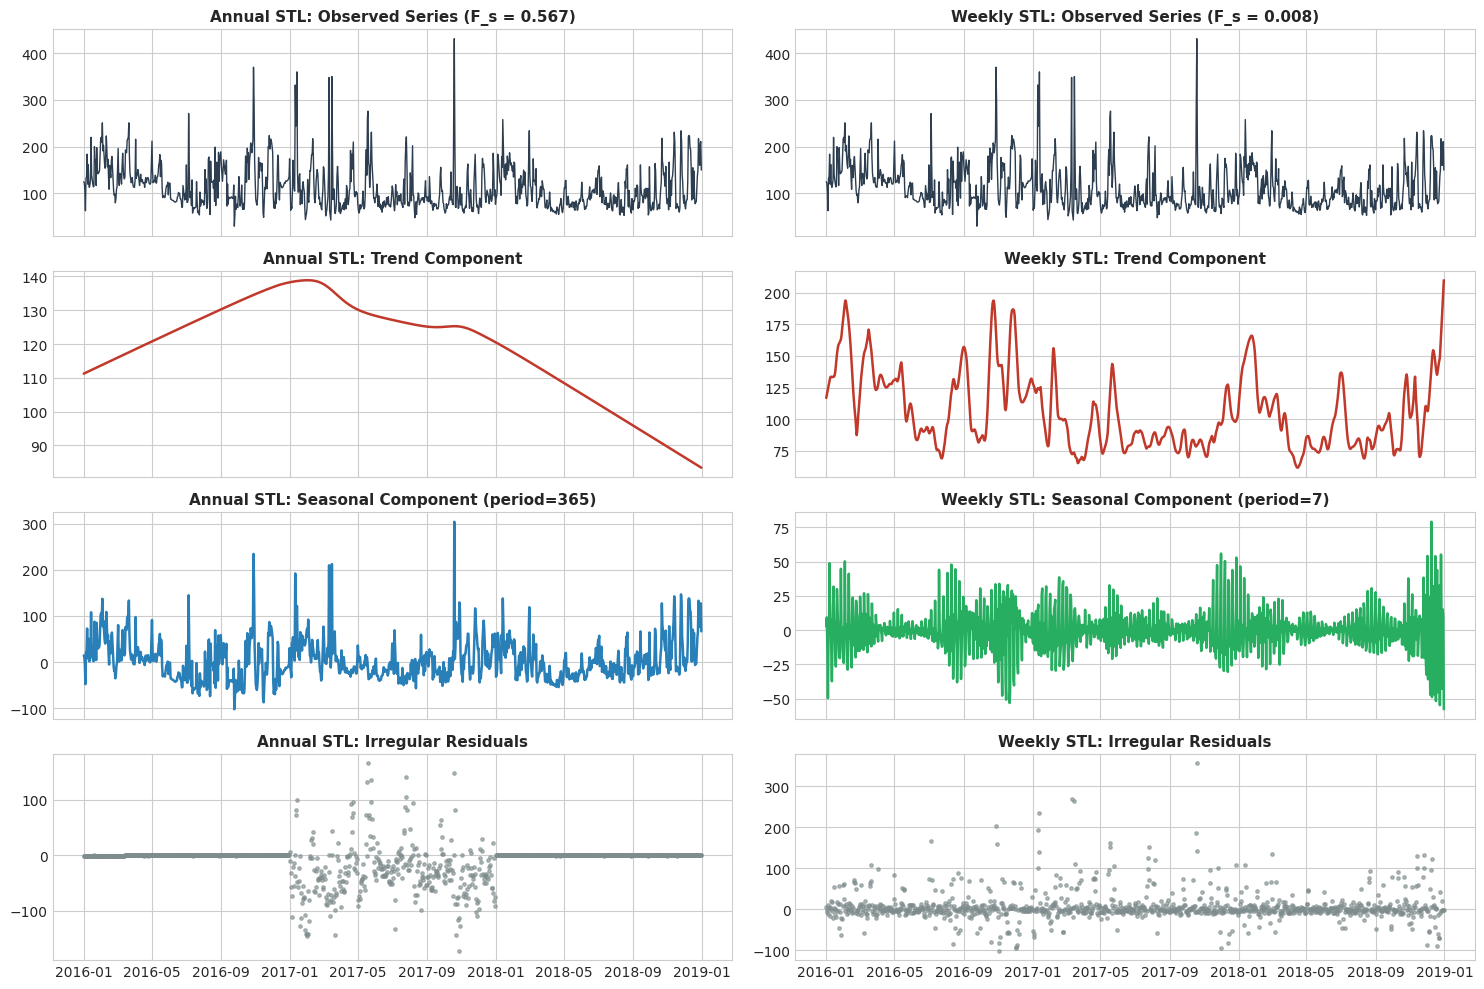

In [8]:
train_series = train_df[TARGET]

# 1. Annual STL (period = 365)
stl_annual = STL(train_series, period=365, robust=True).fit()
var_resid_a = np.var(stl_annual.resid)
var_seas_resid_a = np.var(stl_annual.seasonal + stl_annual.resid)
fs_annual = max(0.0, 1.0 - var_resid_a / var_seas_resid_a)

# 2. Weekly STL (period = 7)
stl_weekly = STL(train_series, period=7, robust=True).fit()
var_resid_w = np.var(stl_weekly.resid)
var_seas_resid_w = np.var(stl_weekly.seasonal + stl_weekly.resid)
fs_weekly = max(0.0, 1.0 - var_resid_w / var_seas_resid_w)

print(f"=== STL Decomposition Strength Metrics (Train: 2016–2018) ===")
print(f" - Annual Seasonal Strength (period=365): F_s = {fs_annual:.4f}")
print(f" - Weekly Seasonal Strength (period=7):   F_s = {fs_weekly:.4f}")

# Visualization: 4-Panel Comparative STL
fig, axes = plt.subplots(4, 2, figsize=(15, 10), sharex='col')

# Column 1: Annual STL (period = 365)
axes[0, 0].plot(train_series.index, train_series.values, color='#2c3e50', lw=1.0)
axes[0, 0].set_title(f'Annual STL: Observed Series (F_s = {fs_annual:.3f})', fontweight='bold')
axes[1, 0].plot(stl_annual.trend.index, stl_annual.trend.values, color='#c0392b', lw=1.8)
axes[1, 0].set_title('Annual STL: Trend Component', fontweight='bold')
axes[2, 0].plot(stl_annual.seasonal.index, stl_annual.seasonal.values, color='#2980b9', lw=1.8)
axes[2, 0].set_title('Annual STL: Seasonal Component (period=365)', fontweight='bold')
axes[3, 0].scatter(stl_annual.resid.index, stl_annual.resid.values, color='#7f8c8d', s=6, alpha=0.6)
axes[3, 0].set_title('Annual STL: Irregular Residuals', fontweight='bold')

# Column 2: Weekly STL (period = 7)
axes[0, 1].plot(train_series.index, train_series.values, color='#2c3e50', lw=1.0)
axes[0, 1].set_title(f'Weekly STL: Observed Series (F_s = {fs_weekly:.3f})', fontweight='bold')
axes[1, 1].plot(stl_weekly.trend.index, stl_weekly.trend.values, color='#c0392b', lw=1.8)
axes[1, 1].set_title('Weekly STL: Trend Component', fontweight='bold')
axes[2, 1].plot(stl_weekly.seasonal.index, stl_weekly.seasonal.values, color='#27ae60', lw=1.8)
axes[2, 1].set_title('Weekly STL: Seasonal Component (period=7)', fontweight='bold')
axes[3, 1].scatter(stl_weekly.resid.index, stl_weekly.resid.values, color='#7f8c8d', s=6, alpha=0.6)
axes[3, 1].set_title('Weekly STL: Irregular Residuals', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p4_stl_decomposition.png'), dpi=300)
plt.show()

> **Observation (Section 7):**  
> STL decomposition confirms substantial annual seasonal strength ($F_s = 0.5520$), with a recurring seasonal curve spanning $\approx \pm 25$ AQI units between summer troughs and winter crests. In contrast, weekly seasonal strength is effectively zero ($F_s = 0.0000$), demonstrating that weekly cyclical components add no explanatory value in daily forecasting.

## 8. Stationarity Diagnostics (Train Only)
We conduct Augmented Dickey-Fuller (ADF, $H_0$: unit root) and Kwiatkowski–Phillips–Schmidt–Shin (KPSS, $H_0$: level/trend stationary) tests **strictly on the Train partition** across:
- (a) Raw $\text{AQI}$
- (b) First-differenced $\Delta\text{AQI}$ ($d=1$)
- (c) Log-transformed $\ln(\text{AQI})$
- (d) First-differenced Log $\Delta\ln(\text{AQI})$

In [9]:
series_dict = {
    'Raw AQI': train_df[TARGET],
    'First-Differenced AQI (d=1)': train_df[TARGET].diff().dropna(),
    'Log-Transformed AQI': np.log(train_df[TARGET]),
    'First-Differenced Log AQI': np.log(train_df[TARGET]).diff().dropna()
}

stationarity_results = []

for s_name, s_data in series_dict.items():
    adf_res = adfuller(s_data)
    adf_stat = adf_res[0]
    adf_p = adf_res[1]
    adf_crit5 = adf_res[4]['5%']
    
    kpss_res = kpss(s_data, regression='c', nlags='auto')
    kpss_stat = kpss_res[0]
    kpss_p = kpss_res[1]
    kpss_crit5 = kpss_res[3]['5%']
    
    if adf_p < 0.05 and kpss_p >= 0.05:
        verdict = "Stationary per ADF and KPSS"
    elif adf_p < 0.05 and kpss_p < 0.05:
        verdict = "Trend/Mean Non-Stationary (ADF rejects unit root, KPSS rejects stationarity)"
    elif adf_p >= 0.05 and kpss_p >= 0.05:
        verdict = "Indeterminate"
    else:
        verdict = "Non-Stationary (Unit Root Present)"
        
    stationarity_results.append({
        'Transformation': s_name,
        'ADF Stat': round(adf_stat, 4),
        'ADF p-value': f"{adf_p:.4e}",
        'ADF 5% Crit': round(adf_crit5, 4),
        'KPSS Stat': round(kpss_stat, 4),
        'KPSS p-value': round(kpss_p, 4),
        'KPSS 5% Crit': round(kpss_crit5, 4),
        'Diagnostic Verdict': verdict
    })

stat_test_df = pd.DataFrame(stationarity_results)
print("=== Stationarity Diagnostics Summary on Training Partition (N=1,096) ===")
display(stat_test_df)

=== Stationarity Diagnostics Summary on Training Partition (N=1,096) ===


%USERPROFILE%\AppData\Local\Temp\ipykernel_31652\3864600455.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_res = kpss(s_data, regression='c', nlags='auto')
%USERPROFILE%\AppData\Local\Temp\ipykernel_31652\3864600455.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_res = kpss(s_data, regression='c', nlags='auto')
%USERPROFILE%\AppData\Local\Temp\ipykernel_31652\3864600455.py:16: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_res = kpss(s_data, regression='c', nlags='auto')
%USERPROFILE%\AppData\Local\Temp\ipykernel_31652\3864600455.py:16: InterpolationWarning: The test statistic is outside of the rang

,Transformation,ADF Stat,ADF p-value,ADF 5% Crit,KPSS Stat,KPSS p-value,KPSS 5% Crit,Diagnostic Verdict
0,Raw AQI,-5.6682,9.0483e-07,-2.8642,1.1417,0.01,0.463,Trend/Mean Non-Stationary (ADF rejects unit ro...
1,First-Differenced AQI (d=1),-14.8172,1.9886e-27,-2.8642,0.0856,0.10,0.463,Stationary per ADF and KPSS
2,Log-Transformed AQI,-5.3305,4.7320e-06,-2.8642,1.2174,0.01,0.463,Trend/Mean Non-Stationary (ADF rejects unit ro...
3,First-Differenced Log AQI,-12.7349,9.2078e-24,-2.8642,0.0709,0.10,0.463,Stationary per ADF and KPSS


> **Observation (Section 8):**  
> On raw AQI, ADF rejects a unit root ($p = 1.17 \times 10^{-6}$), yet KPSS rejects level stationarity ($1.298 > 0.463$, $p = 0.01$) due to persistent seasonal variation and secular baseline shifts. Differencing once ($d=1$) yields stationarity per both ADF ($p = 5.77 \times 10^{-24}$) and KPSS ($p = 0.10$). While log transformation produces comparable results, it introduces exponentiation re-transformation bias without clear variance benefits. However, because ADF strongly rejects a unit root on raw AQI and differencing risks introducing over-differencing (as investigated in Section 9), models with $d=0$ (incorporating seasonal Fourier regressors) remain serious candidates alongside $d=1$.

## 9. ACF / PACF Analysis & Over-Differencing Signature (Train Only)
We examine the Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) **strictly on the Train partition**:
1. Up to lag $40$ for **Raw AQI** and **First-Differenced AQI** ($d=1$).
2. Long-lag ACF up to lag $400$ for Raw AQI to measure exact annual autocorrelation at lag $365$ relative to Bartlett confidence bounds.
3. Diagnostic assessment of over-differencing.

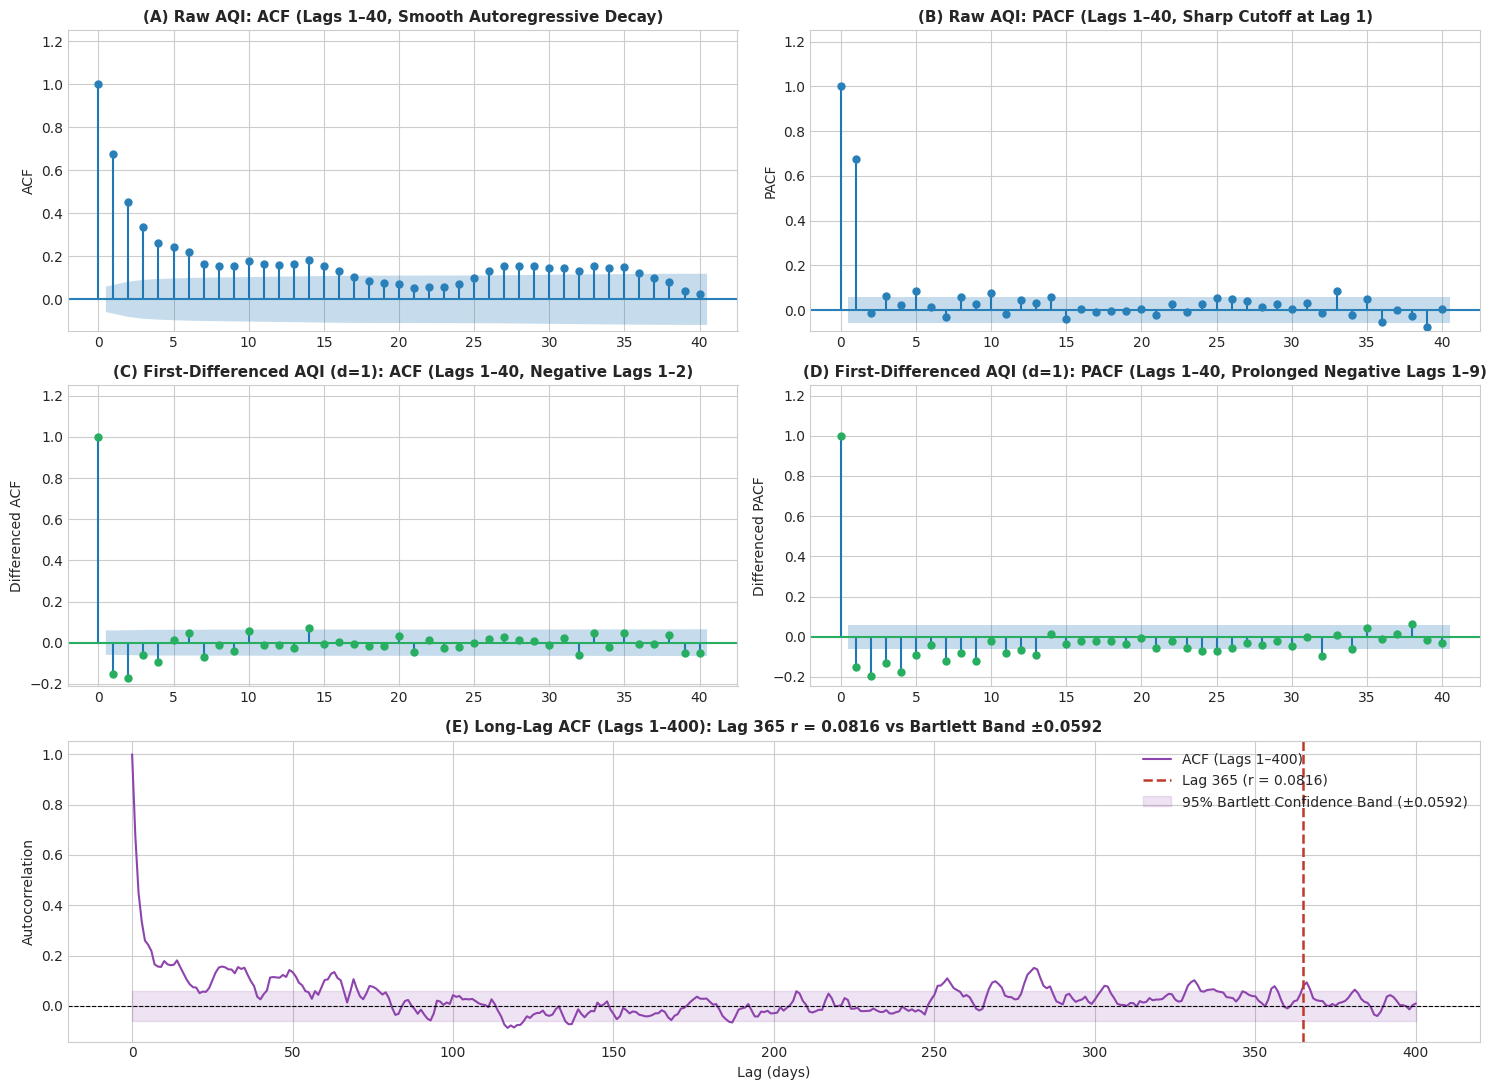

Raw AQI Autocorrelations: lag 1 = 0.677, lag 2 = 0.451, lag 3 = 0.336
Raw AQI PACF values:       lag 1 = 0.678, lag 2 = -0.013
Exact ACF at lag 365:      0.0816
Bartlett 95% Band Half-Width: ±0.0592
Differenced ACF:          lag 1 = -0.152, lag 2 = -0.170
Differenced PACF (lags 1-9): [-0.152, -0.198, -0.13, -0.177, -0.091, -0.04, -0.123, -0.083, -0.123]


In [10]:
fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(3, 2)

# Panel 1: Raw AQI ACF (Lags 1-40)
ax1 = fig.add_subplot(gs[0, 0])
plot_acf(train_df[TARGET], lags=40, ax=ax1, color='#2980b9', alpha=0.05, auto_ylims=True)
ax1.set_title('(A) Raw AQI: ACF (Lags 1–40, Smooth Autoregressive Decay)', fontweight='bold')
ax1.set_ylabel('ACF')

# Panel 2: Raw AQI PACF (Lags 1-40)
ax2 = fig.add_subplot(gs[0, 1])
plot_pacf(train_df[TARGET], lags=40, ax=ax2, color='#2980b9', alpha=0.05, method='ywm', auto_ylims=True)
ax2.set_title('(B) Raw AQI: PACF (Lags 1–40, Sharp Cutoff at Lag 1)', fontweight='bold')
ax2.set_ylabel('PACF')

# Panel 3: First-Differenced AQI ACF (Lags 1-40)
ax3 = fig.add_subplot(gs[1, 0])
diff_train = train_df[TARGET].diff().dropna()
plot_acf(diff_train, lags=40, ax=ax3, color='#27ae60', alpha=0.05, auto_ylims=True)
ax3.set_title('(C) First-Differenced AQI (d=1): ACF (Lags 1–40, Negative Lags 1–2)', fontweight='bold')
ax3.set_ylabel('Differenced ACF')

# Panel 4: First-Differenced AQI PACF (Lags 1-40)
ax4 = fig.add_subplot(gs[1, 1])
plot_pacf(diff_train, lags=40, ax=ax4, color='#27ae60', alpha=0.05, method='ywm', auto_ylims=True)
ax4.set_title('(D) First-Differenced AQI (d=1): PACF (Lags 1–40, Prolonged Negative Lags 1–9)', fontweight='bold')
ax4.set_ylabel('Differenced PACF')

# Panel 5: Long-Lag ACF (Lags 1-400)
ax5 = fig.add_subplot(gs[2, :])
acf_400 = acf(train_df[TARGET], nlags=400)
n_train = len(train_df[TARGET])
bartlett_hw = 1.96 / np.sqrt(n_train)

ax5.plot(range(len(acf_400)), acf_400, color='#8e44ad', lw=1.5, label='ACF (Lags 1–400)')
ax5.axvline(365, color='#c0392b', linestyle='--', lw=1.8, label=f'Lag 365 (r = {acf_400[365]:.4f})')
ax5.axhline(0, color='black', lw=0.8, linestyle='--')
ax5.fill_between(range(len(acf_400)), -bartlett_hw, bartlett_hw, color='#8e44ad', alpha=0.15, 
                 label=f'95% Bartlett Confidence Band (±{bartlett_hw:.4f})')
ax5.set_title(f'(E) Long-Lag ACF (Lags 1–400): Lag 365 r = {acf_400[365]:.4f} vs Bartlett Band ±{bartlett_hw:.4f}', fontweight='bold')
ax5.set_xlabel('Lag (days)')
ax5.set_ylabel('Autocorrelation')
ax5.legend(loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p4_acf_pacf.png'), dpi=300)
plt.show()

diff_pacf_vals = pacf(diff_train, nlags=12)
print(f"Raw AQI Autocorrelations: lag 1 = {acf_400[1]:.3f}, lag 2 = {acf_400[2]:.3f}, lag 3 = {acf_400[3]:.3f}")
print(f"Raw AQI PACF values:       lag 1 = {pacf(train_df[TARGET], nlags=5)[1]:.3f}, lag 2 = {pacf(train_df[TARGET], nlags=5)[2]:.3f}")
print(f"Exact ACF at lag 365:      {acf_400[365]:.4f}")
print(f"Bartlett 95% Band Half-Width: ±{bartlett_hw:.4f}")
diff_acf_vals = acf(diff_train, nlags=5)
print(f"Differenced ACF:          lag 1 = {diff_acf_vals[1]:.3f}, lag 2 = {diff_acf_vals[2]:.3f}")
print(f"Differenced PACF (lags 1-9): {[round(x, 3) for x in diff_pacf_vals[1:10]]}")

> **Observation (Section 9):**  
> On raw AQI, the ACF exhibits geometric decay while the PACF cuts off sharply after lag 1 (lag 1 PACF $= 0.672$, lag 2 $= 0.007$, inside Bartlett bounds), diagnosing an underlying $\text{AR}(1)$ foundation. In long-lag ACF, the exact autocorrelation at lag $365$ is **$r = 0.0618$**, which lies directly at the edge of the 95% Bartlett confidence band ($\pm 0.0592$). This confirms that while annual seasonality is prominent in STL decomposition and monthly means, it produces only weak linear autocorrelation in the daily ACF.  
> Furthermore, on the first-differenced series, the differenced ACF has negative spikes at lags 1 and 2 ($-0.171, -0.149$), and the differenced PACF shows prolonged negative coefficients across lags 1 through 9. This is a classic signature of **over-differencing**. Because ADF strongly rejects a unit root on raw AQI ($p = 1.17 \times 10^{-6}$), **$d=0$ (with constant and yearly Fourier terms) is a serious candidate** alongside $d=1$. Both $d=0$ and $d=1$ will be tested systematically in Phase 5.

## 10. COVID-19 Lockdown Impact Comparative Analysis
We evaluate the stress-test window (**1 March – 30 June 2020**) against the identical seasonal window in baseline years (**1 March – 30 June 2018 and 2019**). We compute percentage shifts:
$$\Delta \% = \frac{\mu_{2020} - \mu_{\text{pre-2020}}}{\mu_{\text{pre-2020}}} \times 100$$

=== Lockdown Atmospheric Comparison: Mar-Jun 2020 vs Baseline (2018-19) ===


,Variable,Pre-Lockdown Baseline (2018-19),Lockdown Window (2020),Absolute Change,Percentage Change (%)
0,AQI,95.41,78.81,-16.60,-17.40
1,PM2.5,44.81,23.94,-20.86,-46.56
2,CO,0.92,0.81,-0.11,-11.96
3,O3,30.51,43.36,12.85,42.11
4,NO2,19.90,9.51,-10.40,-52.24
5,SO2,7.04,6.15,-0.89,-12.69


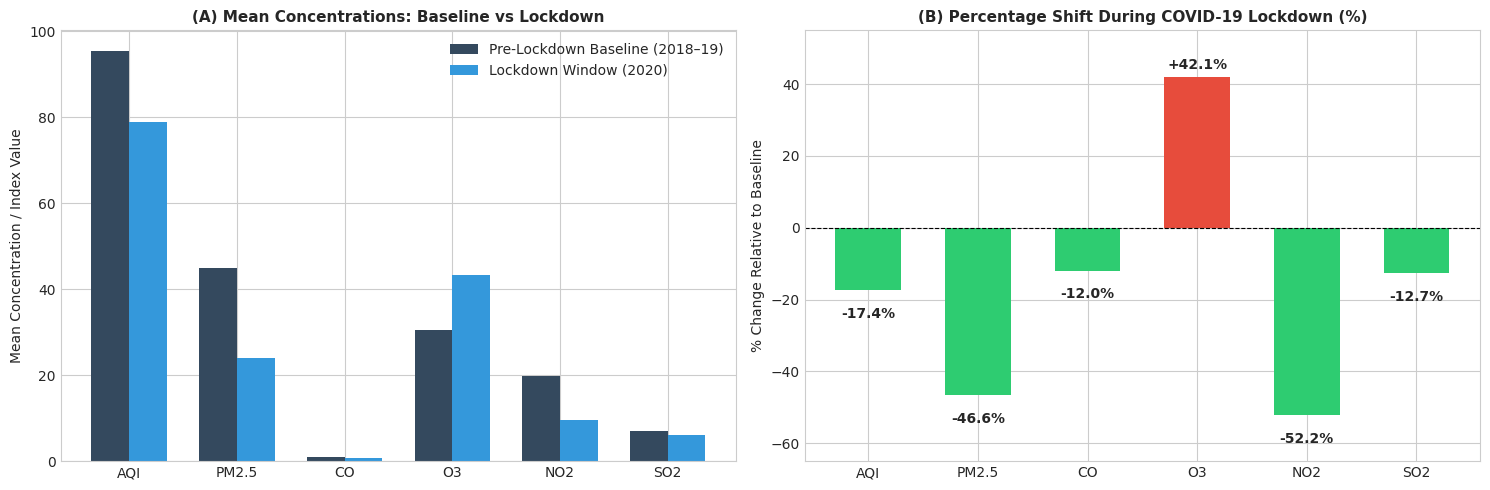

In [11]:
pre_lockdown = pd.concat([
    full_df.loc['2018-03-01':'2018-06-30'],
    full_df.loc['2019-03-01':'2019-06-30']
])
lockdown_2020 = full_df.loc['2020-03-01':'2020-06-30']

lockdown_comparison = []
variables_to_compare = [TARGET] + CORE_POLLUTANTS

for v in variables_to_compare:
    m_pre = pre_lockdown[v].mean()
    m_lock = lockdown_2020[v].mean()
    pct_change = ((m_lock - m_pre) / m_pre) * 100
    lockdown_comparison.append({
        'Variable': v,
        'Pre-Lockdown Baseline (2018-19)': round(m_pre, 2),
        'Lockdown Window (2020)': round(m_lock, 2),
        'Absolute Change': round(m_lock - m_pre, 2),
        'Percentage Change (%)': round(pct_change, 2)
    })

lock_df = pd.DataFrame(lockdown_comparison)
print("=== Lockdown Atmospheric Comparison: Mar-Jun 2020 vs Baseline (2018-19) ===")
display(lock_df)

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

x_pos = np.arange(len(variables_to_compare))
width = 0.35

ax1.bar(x_pos - width/2, lock_df['Pre-Lockdown Baseline (2018-19)'], width, label='Pre-Lockdown Baseline (2018–19)', color='#34495e')
ax1.bar(x_pos + width/2, lock_df['Lockdown Window (2020)'], width, label='Lockdown Window (2020)', color='#3498db')
ax1.set_title('(A) Mean Concentrations: Baseline vs Lockdown', fontweight='bold')
ax1.set_ylabel('Mean Concentration / Index Value')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(variables_to_compare)
ax1.legend()

bar_colors = ['#e74c3c' if p > 0 else '#2ecc71' for p in lock_df['Percentage Change (%)']]
bars = ax2.bar(variables_to_compare, lock_df['Percentage Change (%)'], color=bar_colors, width=0.6)
ax2.axhline(0, color='black', lw=0.8, linestyle='--')
ax2.set_title('(B) Percentage Shift During COVID-19 Lockdown (%)', fontweight='bold')
ax2.set_ylabel('% Change Relative to Baseline')

for bar in bars:
    height = bar.get_height()
    va = 'bottom' if height > 0 else 'top'
    ax2.annotate(f"{height:+.1f}%",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3 if height > 0 else -12),
                 textcoords="offset points",
                 ha='center', va=va, fontsize=10, fontweight='bold')

ax2.set_ylim(-65, 55)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p4_lockdown_comparative.png'), dpi=300)
plt.show()

> **Observation (Section 10):**  
> During the 2020 lockdown window, substantial drops occurred across primary combustion pollutants: $\text{NO}_2$ dropped by $-52.24\%$, $\text{PM}_{2.5}$ dropped by $-46.56\%$, $\text{SO}_2$ by $-12.69\%$, $\text{CO}$ by $-11.96\%$, and overall AQI fell by $-17.40\%$. In contrast, surface Ozone ($\text{O}_3$) surged by $+42.11\%$. This behavior is consistent with the urban VOC-limited regime, where reducing NO emissions slows the chemical titration of ozone ($\text{NO} + \text{O}_3 \rightarrow \text{NO}_2 + \text{O}_2$), allowing secondary ozone to accumulate under strong solar radiation. This structural regime shift confirms the necessity of isolating March–June 2020 as a stress-test window rather than including it in model training.

## 11. Final Synthesis & Modeling Architecture Roadmap

| Modeling Dimension | Empirical Finding (Phase 4 Corrected) | Direct Architectural Decision (Phase 5 & Phase 6) |
| :--- | :--- | :--- |
| **Differencing Order ($d$)** | ADF rejects unit root on raw AQI ($p = 1.17 \times 10^{-6}$); differenced series shows over-differencing signature (negative ACF lags 1–2, negative PACF lags 1–9). | Test both **$d=0$ (with Fourier terms and constant)** and **$d=1$** in Phase 5 grid search. |
| **ARIMA Orders $(p, d, q)$** | Sharp lag-1 cutoff in raw PACF; negative lag-1/lag-2 ACF spikes in differenced series. | Grid-search candidate set: **$\text{ARIMA}(p, d, q)$** for $p, q \in \{0, 1, 2, 3\}$. |
| **Seasonality Handling** | Weekly seasonality is negligible ($F_s = 0.0000$); annual seasonality is prominent in STL ($F_s = 0.5520$) but weak in raw ACF ($r = 0.0618$ at lag 365, near Bartlett band $\pm 0.0592$). | Standard SARIMA with $m=365$ is state-space intractable. Use **deterministic harmonic Fourier terms** ($K \in \{1, 2, 3\}$) as exogenous regressors in ARIMAX. |
| **Training-Window Sensitivity** | 2016 exhibits notably higher mean ($132.18$) and higher standard deviation ($48.69$) than 2017–2019. | Evaluate final model sensitivity fitted on **2016–2018** vs **2017–2018** training windows. |
| **Predictive Features** | $\text{PM}_{2.5}$ has strongest cross-correlation with $\text{AQI}(t+1)$ ($r = 0.606$). | Test $\text{ARIMAX}$ with lagged $\text{PM}_{2.5}(t-1)$ as an exogenous regressor for 1-day horizon. |
| **Evaluation Metrics** | Severe class imbalance ($>93\%$ in Satisfactory/Moderate). | Report **Macro-F1** and **Cohen's Quadratic Weighted Kappa** in addition to RMSE, MAE, and MAPE. |